# 01 · Pipeline walkthrough

Builds the ONNX pipeline with the configuration used in the Android app, runs it stage by stage (preprocess → detector → extractor → search → postprocess) on a photo of Cáceres, and then runs the fused end-to-end model on a few more images.

The landmark database is loaded from `android_app/app/src/main/assets/pipeline/places_db.bin` (the original Cáceres image dataset is not public).

In [ ]:
# Run from the repository root so that relative paths and package imports resolve
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [71]:
from landmark_detection.pipeline import Pipeline_Landmark_Detection
from landmark_detection.utils import show_image, show_bboxes, show_similarity_search
from landmark_detection.utils import load_places_db

import os
import pandas as pd
import pickle
import numpy as np

In [72]:
VERSION = "app"

# DATABASE
force_rebuild = False
save_every = 500
min_area = 0.15
min_sim_db = 0.90

# PIPELINE
detector_file = "yolov8n-oiv7.pt"
extractor_onnx_file = "cvnet-sg-v" + str(VERSION) + ".onnx"
pipeline_onnx_file = "pipeline-yolo-cvnet-sg-v" + str(VERSION) + ".onnx"
image_dim = (640, 640)
allowed_classes = [41,68,70,74,87,95,113,144,150,158,164,165,193,205,212,224,257,
                    298,310,335,351,354,390,393,401,403,439,442,457,466,489,510,512,
                    514,524,530,531,543,546,554,565,573,580,588,591]
score_thresh = 0.05
iou_thresh = 0.40
scales = [0.7071, 1.0, 1.4142]
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]
rgem_pr = 8
rgem_size = 5
gem_p = 3
sgem_ps = 10.0
sgem_infinity = True
eps = 1e-8
topk = 6
min_sim = 0.89
min_votes = 0.33
remove_inner_boxes = 0.9
join_boxes = True

In [3]:
pipeline = Pipeline_Landmark_Detection(
        detector_file = detector_file,
        extractor_onnx_file = extractor_onnx_file,
        pipeline_onnx_file = pipeline_onnx_file,
        image_dim = image_dim,
        allowed_classes = allowed_classes,
        score_thresh = score_thresh,
        iou_thresh = iou_thresh,
        scales = scales,
        mean = mean,
        std = std,
        rgem_pr = rgem_pr,
        rgem_size = rgem_size,
        gem_p = gem_p,
        sgem_ps = sgem_ps,
        sgem_infinity = sgem_infinity,
        eps = eps,
        topk = topk,
        min_sim = min_sim,
        min_votes = min_votes,
        remove_inner_boxes = remove_inner_boxes,
        join_boxes = join_boxes
)

Creando versión ONNX del preprocess
Instanciando el preprocessor
Creando versión ONNX del detector
Ultralytics 8.3.146  Python-3.11.11 torch-2.7.0+cpu CPU (Intel Core(TM) i5-9300HF 2.40GHz)
YOLOv8n summary (fused): 72 layers, 3,492,527 parameters, 0 gradients, 10.5 GFLOPs

PyTorch: starting from '<repo>\landmark_detection\models\yolov8n-oiv7.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 605, 8400) (6.9 MB)

ONNX: starting export with onnx 1.17.0 opset 16...
ONNX: slimming with onnxslim 0.1.54...
ONNX: export success  2.0s, saved as '<repo>\landmark_detection\models\yolov8n-oiv7.onnx' (13.5 MB)

Export complete (2.6s)
Results saved to <repo>\landmark_detection\models
Predict:         yolo predict task=detect model=<repo>\landmark_detection\models\yolov8n-oiv7.onnx imgsz=640  
Validate:        yolo val task=detect model=<repo>\landmark_detection\models\yolov8n-oiv7.onnx imgsz=640 data=/usr/src/ultralytics/ultralytics/cfg/datasets/open-images-v7.yaml  
Visualize:     

In [ ]:
# Cáceres embedding database shipped with the Android app
APP_ASSETS_PATH = os.path.join("android_app", "app", "src", "main", "assets", "pipeline")
CACERES_LANDMARK_NAMES_PATH = os.path.join("configs", "caceres_landmarks.yaml")

places_db_cac = load_places_db(os.path.join(APP_ASSETS_PATH, "places_db.bin"))
places_db_cac.shape

In [7]:
TEST_IMG_PATH = os.path.join("test_images", "caceres-14.jpg")

In [8]:
image_proc, orig_size, places_db = pipeline.preprocess(TEST_IMG_PATH, places_db_cac)

print('image_proc.shape: ', image_proc.shape)
print('orig_size:', orig_size)
print('places_db.shape:', places_db.shape)

image_proc.shape:  (1, 3, 640, 640)
orig_size: [       3072        4080]
places_db.shape: (945, 2049)


In [9]:
detections, image_proc, places_db, orig_size = pipeline.detect(image_proc, places_db_cac, orig_size)

print('detections[0].shape: ', detections[0].shape)
print('image_proc.shape: ', image_proc.shape)
print('places_db.shape:', places_db.shape)
print('orig_size:', orig_size)

detections[0].shape:  (605, 8400)
image_proc.shape:  (1, 3, 640, 640)
places_db.shape: (945, 2049)
orig_size: [       3072        4080]


In [10]:
boxes, descriptors, places_db, orig_size = pipeline.extract(detections, image_proc, places_db_cac, orig_size)

print('boxes.shape: ', boxes.shape)
print('descriptors.shape: ', descriptors.shape)
print('places_db.shape:', places_db_cac.shape)
print('orig_size:', orig_size)

boxes.shape:  (5, 4)
descriptors.shape:  (5, 2048)
places_db.shape: (945, 2049)
orig_size: [       3072        4080]


In [11]:
boxes

array([[          0,           0,         639,         639],
       [     1.4263,    -0.83691,      343.29,       581.7],
       [     341.71,      159.75,      640.77,      566.48],
       [     552.64,     0.71829,      640.24,      374.86],
       [     334.62,      424.76,      364.26,      555.69]], dtype=float32)

Encontradas 6 cajas:
  Clase None None @ None → [0.0,0.0,3067.2,4073.6]
  Clase None None @ None → [6.8,-5.3,1647.8,3708.3]
  Clase None None @ None → [1640.2,1018.4,3075.7,3611.3]
  Clase None None @ None → [2652.7,4.6,3073.2,2389.7]
  Clase None None @ None → [1606.2,2707.8,1748.4,3542.5]
  Clase None None @ None → [96.0,127.5,336.0,446.2]


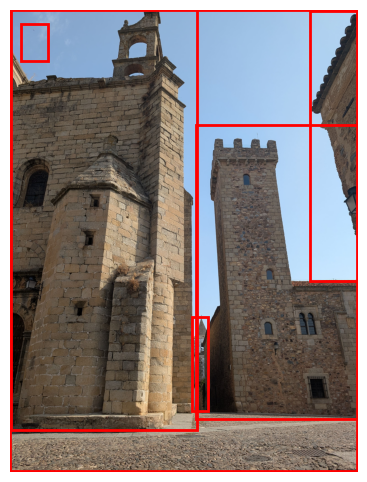

In [13]:
scaled_boxes, _, _ = pipeline.postprocess(boxes, [], [], orig_size)
show_bboxes(TEST_IMG_PATH, scaled_boxes)

In [14]:
boxes_out, scores_out, classes_out, orig_size = pipeline.search(boxes, descriptors, places_db_cac, orig_size)

print('boxes_out.shape: ', boxes_out.shape)
print('scores_out.shape: ', scores_out.shape)
print('classes_out.shape:', classes_out.shape)
print('orig_size:', orig_size)

boxes_out.shape:  (2, 4)
scores_out.shape:  (2,)
classes_out.shape: (2,)
orig_size: [       3072        4080]


In [15]:
classes_out

array([10, 11])

In [16]:
scaled_boxes, final_scores, final_classes = pipeline.postprocess(boxes_out, scores_out, classes_out, orig_size)

print('scaled_boxes.shape: ', scaled_boxes.shape)
print('final_scores.shape: ', final_scores.shape)
print('final_classes.shape:', final_classes.shape)

scaled_boxes.shape:  (3, 4)
final_scores.shape:  (3,)
final_classes.shape: (3,)


In [17]:
final_scores

array([    0.96802,     0.95666,           0], dtype=float32)

In [18]:
final_classes

array([10, 11, -1])

Encontradas 3 cajas:
  Clase 10 Iglesia de San Mateo @ 0.97 → [6.8,-5.3,1647.8,3708.3]
  Clase 11 Palacio de los CÃ¡ceres-Ovando @ 0.96 → [1640.2,1018.4,3075.7,3611.3]
  Clase -1 No detected @ 0.00 → [96.0,127.5,336.0,446.2]


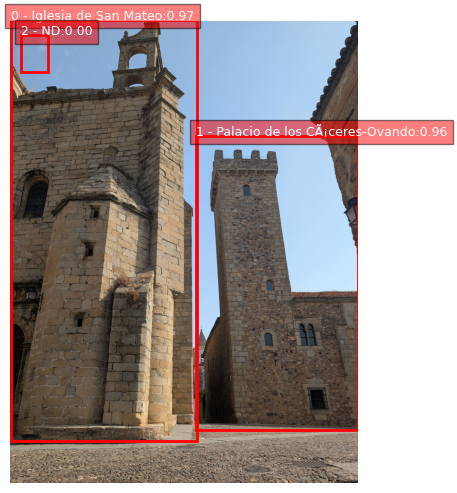

In [19]:
show_bboxes(TEST_IMG_PATH, scaled_boxes, CACERES_LANDMARK_NAMES_PATH, final_classes, final_scores)

Encontradas 2 cajas:
  Clase 1 Torre de Bujaco @ 0.96 → [1030.5,1092.6,2206.1,2850.1]
  Clase -1 No detected @ 0.00 → [96.0,127.5,336.0,446.2]


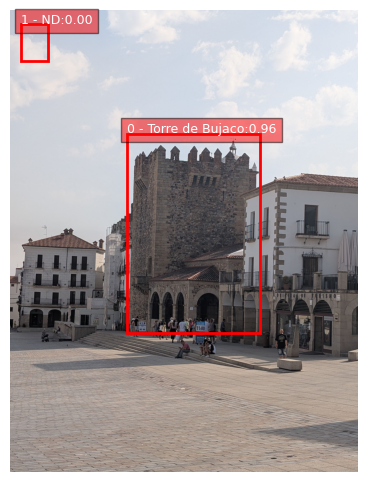

In [24]:
TEST_IMG2_PATH = os.path.join("test_images", "caceres-5.jpg")
pipeline_boxes, pipeline_scores, pipelinel_classes = pipeline.run(TEST_IMG2_PATH, places_db)
show_bboxes(TEST_IMG2_PATH, pipeline_boxes, CACERES_LANDMARK_NAMES_PATH, pipelinel_classes, pipeline_scores)

Encontradas 2 cajas:
  Clase 2 Concatedral de Santa MarÃ­a @ 0.96 → [541.0,747.8,2153.6,2937.5]
  Clase -1 No detected @ 0.00 → [96.0,127.5,336.0,446.2]


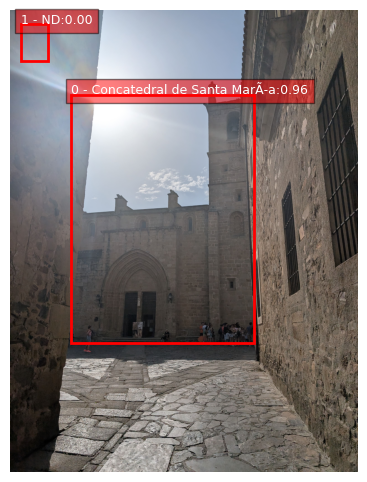

In [26]:
TEST_IMG2_PATH = os.path.join("test_images", "caceres-7.jpg")
pipeline_boxes, pipeline_scores, pipelinel_classes = pipeline.run(TEST_IMG2_PATH, places_db)
show_bboxes(TEST_IMG2_PATH, pipeline_boxes, CACERES_LANDMARK_NAMES_PATH, pipelinel_classes, pipeline_scores)

Encontradas 2 cajas:
  Clase 6 Iglesia de San Francisco Javier @ 0.96 → [23.4,1066.8,1886.5,3014.2]
  Clase -1 No detected @ 0.00 → [96.0,127.5,336.0,446.2]


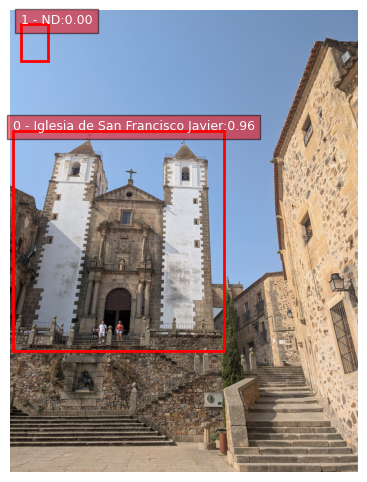

In [30]:
TEST_IMG2_PATH = os.path.join("test_images", "caceres-11.jpg")
pipeline_boxes, pipeline_scores, pipelinel_classes = pipeline.run(TEST_IMG2_PATH, places_db)
show_bboxes(TEST_IMG2_PATH, pipeline_boxes, CACERES_LANDMARK_NAMES_PATH, pipelinel_classes, pipeline_scores)

Encontradas 3 cajas:
  Clase 10 Iglesia de San Mateo @ 0.96 → [-1.1,-13.0,1549.4,3341.7]
  Clase 11 Palacio de los CÃ¡ceres-Ovando @ 0.93 → [1650.7,744.8,2402.4,3104.1]
  Clase -1 No detected @ 0.00 → [96.0,127.5,336.0,446.2]


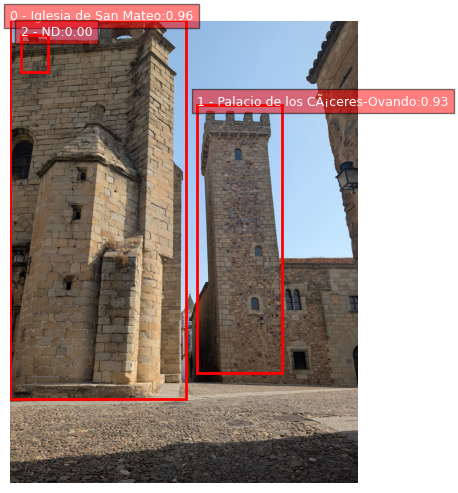

In [32]:
TEST_IMG2_PATH = os.path.join("test_images", "caceres-13.jpg")
pipeline_boxes, pipeline_scores, pipelinel_classes = pipeline.run(TEST_IMG2_PATH, places_db)
show_bboxes(TEST_IMG2_PATH, pipeline_boxes, CACERES_LANDMARK_NAMES_PATH, pipelinel_classes, pipeline_scores)

Encontradas 2 cajas:
  Clase 6 Iglesia de San Francisco Javier @ 0.97 → [6.9,296.7,3033.5,2353.8]
  Clase -1 No detected @ 0.00 → [96.0,128.0,336.0,448.0]


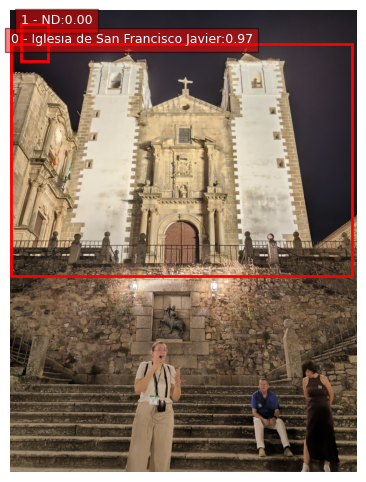

In [44]:
TEST_IMG2_PATH = os.path.join("test_images", "caceres-25.jpg")
pipeline_boxes, pipeline_scores, pipelinel_classes = pipeline.run(TEST_IMG2_PATH, places_db)
show_bboxes(TEST_IMG2_PATH, pipeline_boxes, CACERES_LANDMARK_NAMES_PATH, pipelinel_classes, pipeline_scores)

Encontradas 2 cajas:
  Clase 10 Iglesia de San Mateo @ 0.93 → [-0.0,13.8,918.1,1471.0]
  Clase -1 No detected @ 0.00 → [28.7,64.0,100.5,224.0]


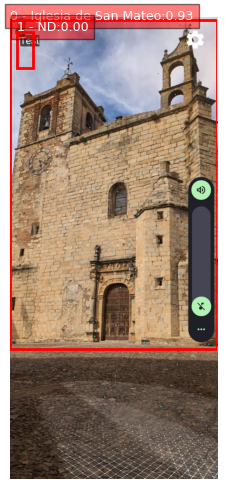

In [58]:
TEST_IMG2_PATH = os.path.join("test_images", "caceres-38.jpg")
pipeline_boxes, pipeline_scores, pipelinel_classes = pipeline.run(TEST_IMG2_PATH, places_db)
show_bboxes(TEST_IMG2_PATH, pipeline_boxes, CACERES_LANDMARK_NAMES_PATH, pipelinel_classes, pipeline_scores)